# Experiment 0 — Figure 2 theo dữ liệu và phương pháp gốc

Python-only: historical JHU → published synthetic library/parameters → thin
plate GAM/GCV → UQ → 1–4 week forecasts → MAE/WIS và Figure 2.

Đã tải dữ liệu đúng nguồn README. `figure2_retrospective` giữ quy tắc UQ hồi
cứu của script; không gọi đây là real-time causal. Run 50 bang cũ là legacy,
không phải kết quả historical/GAM mới.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/run_pipeline.py').exists())
OUT=ROOT/'outputs/experiment_0_source'
DATA=ROOT/'outputs/paper_data'
REBUILD=False  # True: chạy lại bằng cache thật; không chạy BO
if REBUILD:
    subprocess.run([sys.executable,'-u',str(ROOT/'experiments/reproduction/experiment_0.py'),
                    '--paper-data',str(DATA),'--output-dir',str(OUT)],check=True,cwd=ROOT)
if not (OUT/'summary.json').exists():
    raise FileNotFoundError('Chạy fetch_paper_data.py rồi experiment_0.py theo README reproduction.')
summary=json.loads((OUT/'summary.json').read_text())
protocol=json.loads((OUT/'protocol.json').read_text())
print('Protocol:',protocol['name'])
print('Report:',OUT/'report.md')
print('Full paper reproduction:',summary['full_paper_reproduction'])

Protocol: figure2_source_v2
Report: /Users/nguyentranglinh/infectious-disease-forecasting/outputs/experiment_0_source/report.md
Full paper reproduction: False


## 1. Dữ liệu đã lấy từ đâu?

`covidData` chỉ định commit JHU cho từng issue date. LANL yêu cầu dữ liệu
Saturday+1, sau đó ghi nhãn Saturday; không đổi thành thông tin có sẵn vào
Saturday. Dữ liệu weekly được tổng county theo bang, sai phân cumulative rồi
cộng Chủ nhật–Thứ bảy. Scoring dùng final truth do LANL cung cấp.

Các file forecast dưới đây là submission gốc của COVIDHub, không phải
persistence do project tự sinh. Không điền forecast ở những ngày archive thiếu.

In [2]:
provenance=json.loads((DATA/'provenance.json').read_text())
vintages=[r for r in provenance['sources'] if 'as_of_label' in r]
display(pd.DataFrame(vintages))
hub=pd.read_csv(DATA/'hub_forecasts.csv')
display(hub.groupby(['model','forecast_date'],as_index=False).agg(rows=('value','size')))
print('Snapshot states:',', '.join(provenance['states']))
print(provenance['protocol'])

,as_of_label,requested_as_of,issue_date,source_commit,source_url
0,2020-08-15,2020-08-16,2020-08-16,39ab57968cdcd07f665a20943b113a65ea45d33f,https://raw.githubusercontent.com/CSSEGISandDa...
1,2020-08-22,2020-08-23,2020-08-23,4eb0bbe2bf8391e58227026b9917a03faca89ad2,https://raw.githubusercontent.com/CSSEGISandDa...
2,2020-08-29,2020-08-30,2020-08-30,56f5b3ce5d18599ebcff7bbcaa0dd9842ae099ba,https://raw.githubusercontent.com/CSSEGISandDa...
3,2020-09-05,2020-09-06,2020-09-06,31d74e0f6fb9cda474ba69c36e59d309ba6aabfc,https://raw.githubusercontent.com/CSSEGISandDa...


,model,forecast_date,rows
0,COVIDhub-4_week_ensemble,2020-08-10,128
1,COVIDhub-baseline,2020-04-13,128
2,COVIDhub-baseline,2020-05-18,128
3,COVIDhub-baseline,2020-06-15,128
4,COVIDhub-baseline,2020-07-13,128
5,COVIDhub-baseline,2020-08-10,128


Snapshot states: California, Florida, New York, Texas
covidData JHU state aggregation; unadjusted incidence, Sunday-Saturday; LANL Saturday+1 retrieval


## 2. Phương pháp và lịch dự báo

Giữ tham số đã công bố, không ép BO Python chọn lại đúng winner R. Thư viện
đầy đủ: 18.387 attempts/family × 3 = 55.161 attempts, 54.081 accepted curves.
Thin plate regression spline dùng rank round(n/2) và GCV. Embedding riêng
Figure 2 bỏ bridge; NB initial sizes [20,10,6,6].

Source UQ dùng final labels của mọi forecast đã phát trước đó, kể cả target
chưa tới. Đối chứng `smoa_matured_uq` chỉ dùng target đã tới hạn, cùng points;
riêng historical snapshot đầu kỳ vẫn là frozen August như source.

In [3]:
display(pd.DataFrame([protocol['published_params']]))
for key in ['history','smoothing','embedding','warmup','calibration','causal_sensitivity']:
    print(f'{key}: {protocol[key]}')
plan=pd.read_csv(OUT/'schedule.csv')
assert len(plan)==24
assert (pd.to_datetime(plan.first_target_end_date)-pd.to_datetime(plan.forecast_origin)).dt.days.eq(7).all()
display(plan)

,num_curves,k,closest
0,18387,5,4422


history: Frozen JHU issue 2020-08-16, labelled 2020-08-15 by LANL
smoothing: Gaussian thin plate regression spline; k=max(3,round(n/2)); GCV
embedding: figure_2.R diff(y), omit bridge
warmup: No pre-Feb29 warmup: Jan25-Feb22 has 5 rows, failing source >=6 condition
calibration: figure2_retrospective: all earlier issued forecasts and final labels, even unmatured targets
causal_sensitivity: same point forecasts, matured final labels only; not real-time vintages before August


,series,forecast_origin,forecast_date,first_target_end_date,last_target_end_date
0,California,2020-03-14,2020-03-16,2020-03-21,2020-04-11
1,California,2020-04-11,2020-04-13,2020-04-18,2020-05-09
2,California,2020-05-16,2020-05-18,2020-05-23,2020-06-13
3,California,2020-06-13,2020-06-15,2020-06-20,2020-07-11
4,California,2020-07-11,2020-07-13,2020-07-18,2020-08-08
5,California,2020-08-08,2020-08-10,2020-08-15,2020-09-05
6,Florida,2020-03-14,2020-03-16,2020-03-21,2020-04-11
7,Florida,2020-04-11,2020-04-13,2020-04-18,2020-05-09
8,Florida,2020-05-16,2020-05-18,2020-05-23,2020-06-13
9,Florida,2020-06-13,2020-06-15,2020-06-20,2020-07-11


## 3. MAE, WIS và coverage

MAE/WIS càng thấp càng tốt. **Số targets khác nhau giữa các model** vì Hub
chưa có incident-case forecasts ở nhiều ngày early; không xếp hạng bằng mean
trên những sample khác nhau. Persistence chỉ là diagnostic thêm của Python.

In [4]:
metrics=pd.read_csv(OUT/'metrics.csv')
display(metrics.round(3))
display(pd.read_csv(OUT/'metrics_by_horizon.csv').round(3))
scores=pd.read_csv(OUT/'scores.csv')
smoa=scores.loc[scores.model=='smoa']
assert len(smoa)==96 and set(smoa.horizon)=={1,2,3,4}
assert not scores.duplicated(['series','forecast_origin','horizon','model']).any()
print(f"sMOA, 96 targets: MAE={smoa.abs_error.mean():,.2f}; WIS={smoa.wis.mean():,.2f}")

,model,n,mae,wis,coverage_95,width_95
0,COVIDhub-4_week_ensemble,16,8990.125,4775.144,0.875,33538.062
1,COVIDhub-baseline,80,10946.825,7921.124,0.700,26831.682
2,persistence,96,11590.698,8612.024,0.781,72896.135
3,smoa,96,10570.349,7431.191,0.833,73675.597
4,smoa_matured_uq,96,10570.349,7447.886,0.833,74169.771


,model,horizon,n,mae,wis,coverage_95
0,COVIDhub-4_week_ensemble,1,4,11669.750,7682.516,0.500
1,COVIDhub-4_week_ensemble,2,4,5227.000,2818.329,1.000
2,COVIDhub-4_week_ensemble,3,4,9217.250,4088.514,1.000
3,COVIDhub-4_week_ensemble,4,4,9846.500,4511.218,1.000
4,COVIDhub-baseline,1,20,6159.600,4482.983,0.600
5,COVIDhub-baseline,2,20,8415.400,5952.944,0.800
6,COVIDhub-baseline,3,20,12189.600,8924.962,0.750
7,COVIDhub-baseline,4,20,17022.700,12323.606,0.650
8,persistence,1,24,5598.583,4148.859,0.833
9,persistence,2,24,9180.833,7355.058,0.833


sMOA, 96 targets: MAE=10,570.35; WIS=7,431.19


## 4. So sánh trên targets chung

Lấy giao chính xác series/origin/target/horizon có đủ sMOA, official baseline
và official 4-week ensemble. Tập giao này chỉ có 16 targets, chưa đại diện cho
ranking trên toàn bộ pandemic hoặc toàn bộ COVIDHub models.

In [5]:
paired=pd.read_csv(OUT/'paired_scores.csv')
display(pd.read_csv(OUT/'paired_metrics.csv').round(3))
keys=['series','forecast_origin','target_end_date','horizon']
sets=[set(map(tuple,g[keys].to_numpy())) for _,g in paired.groupby('model')]
assert len(sets)==3 and all(s==sets[0] for s in sets)
display(paired.groupby(['model','horizon'],as_index=False).agg(n=('wis','size'),MAE=('abs_error','mean'),WIS=('wis','mean')).round(3))

,model,n,mae,wis
0,COVIDhub-4_week_ensemble,16,8990.125,4775.144
1,COVIDhub-baseline,16,12552.375,7368.116
2,smoa,16,6166.375,5331.161


,model,horizon,n,MAE,WIS
0,COVIDhub-4_week_ensemble,1,4,11669.750,7682.516
1,COVIDhub-4_week_ensemble,2,4,5227.000,2818.329
2,COVIDhub-4_week_ensemble,3,4,9217.250,4088.514
3,COVIDhub-4_week_ensemble,4,4,9846.500,4511.218
4,COVIDhub-baseline,1,4,11533.500,8762.591
5,COVIDhub-baseline,2,4,8946.000,4519.465
6,COVIDhub-baseline,3,4,13411.500,7130.816
7,COVIDhub-baseline,4,4,16318.500,9059.592
8,smoa,1,4,13924.750,6475.983
9,smoa,2,4,2840.625,4762.912


## 5. Figure 2 gốc và Figure 2 Python

Cùng thứ tự: 4 bang theo cột; 4-week ensemble, baseline, sMOA theo hàng.
Chung y-scale; reported data cam, point đen, 50%/95% intervals xanh. Đường
reported data được lấy ở các mốc như script gốc, không nối mọi điểm weekly.
Mốc cuối 05/09 giữ đủ forecast horizon thứ tư.

Hình paper: PLOS, CC0; [nguồn](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1013203).
Không suy original sMOA numeric values từ pixel thành ground truth.

**Paper Figure 2 — PLOS, CC0**

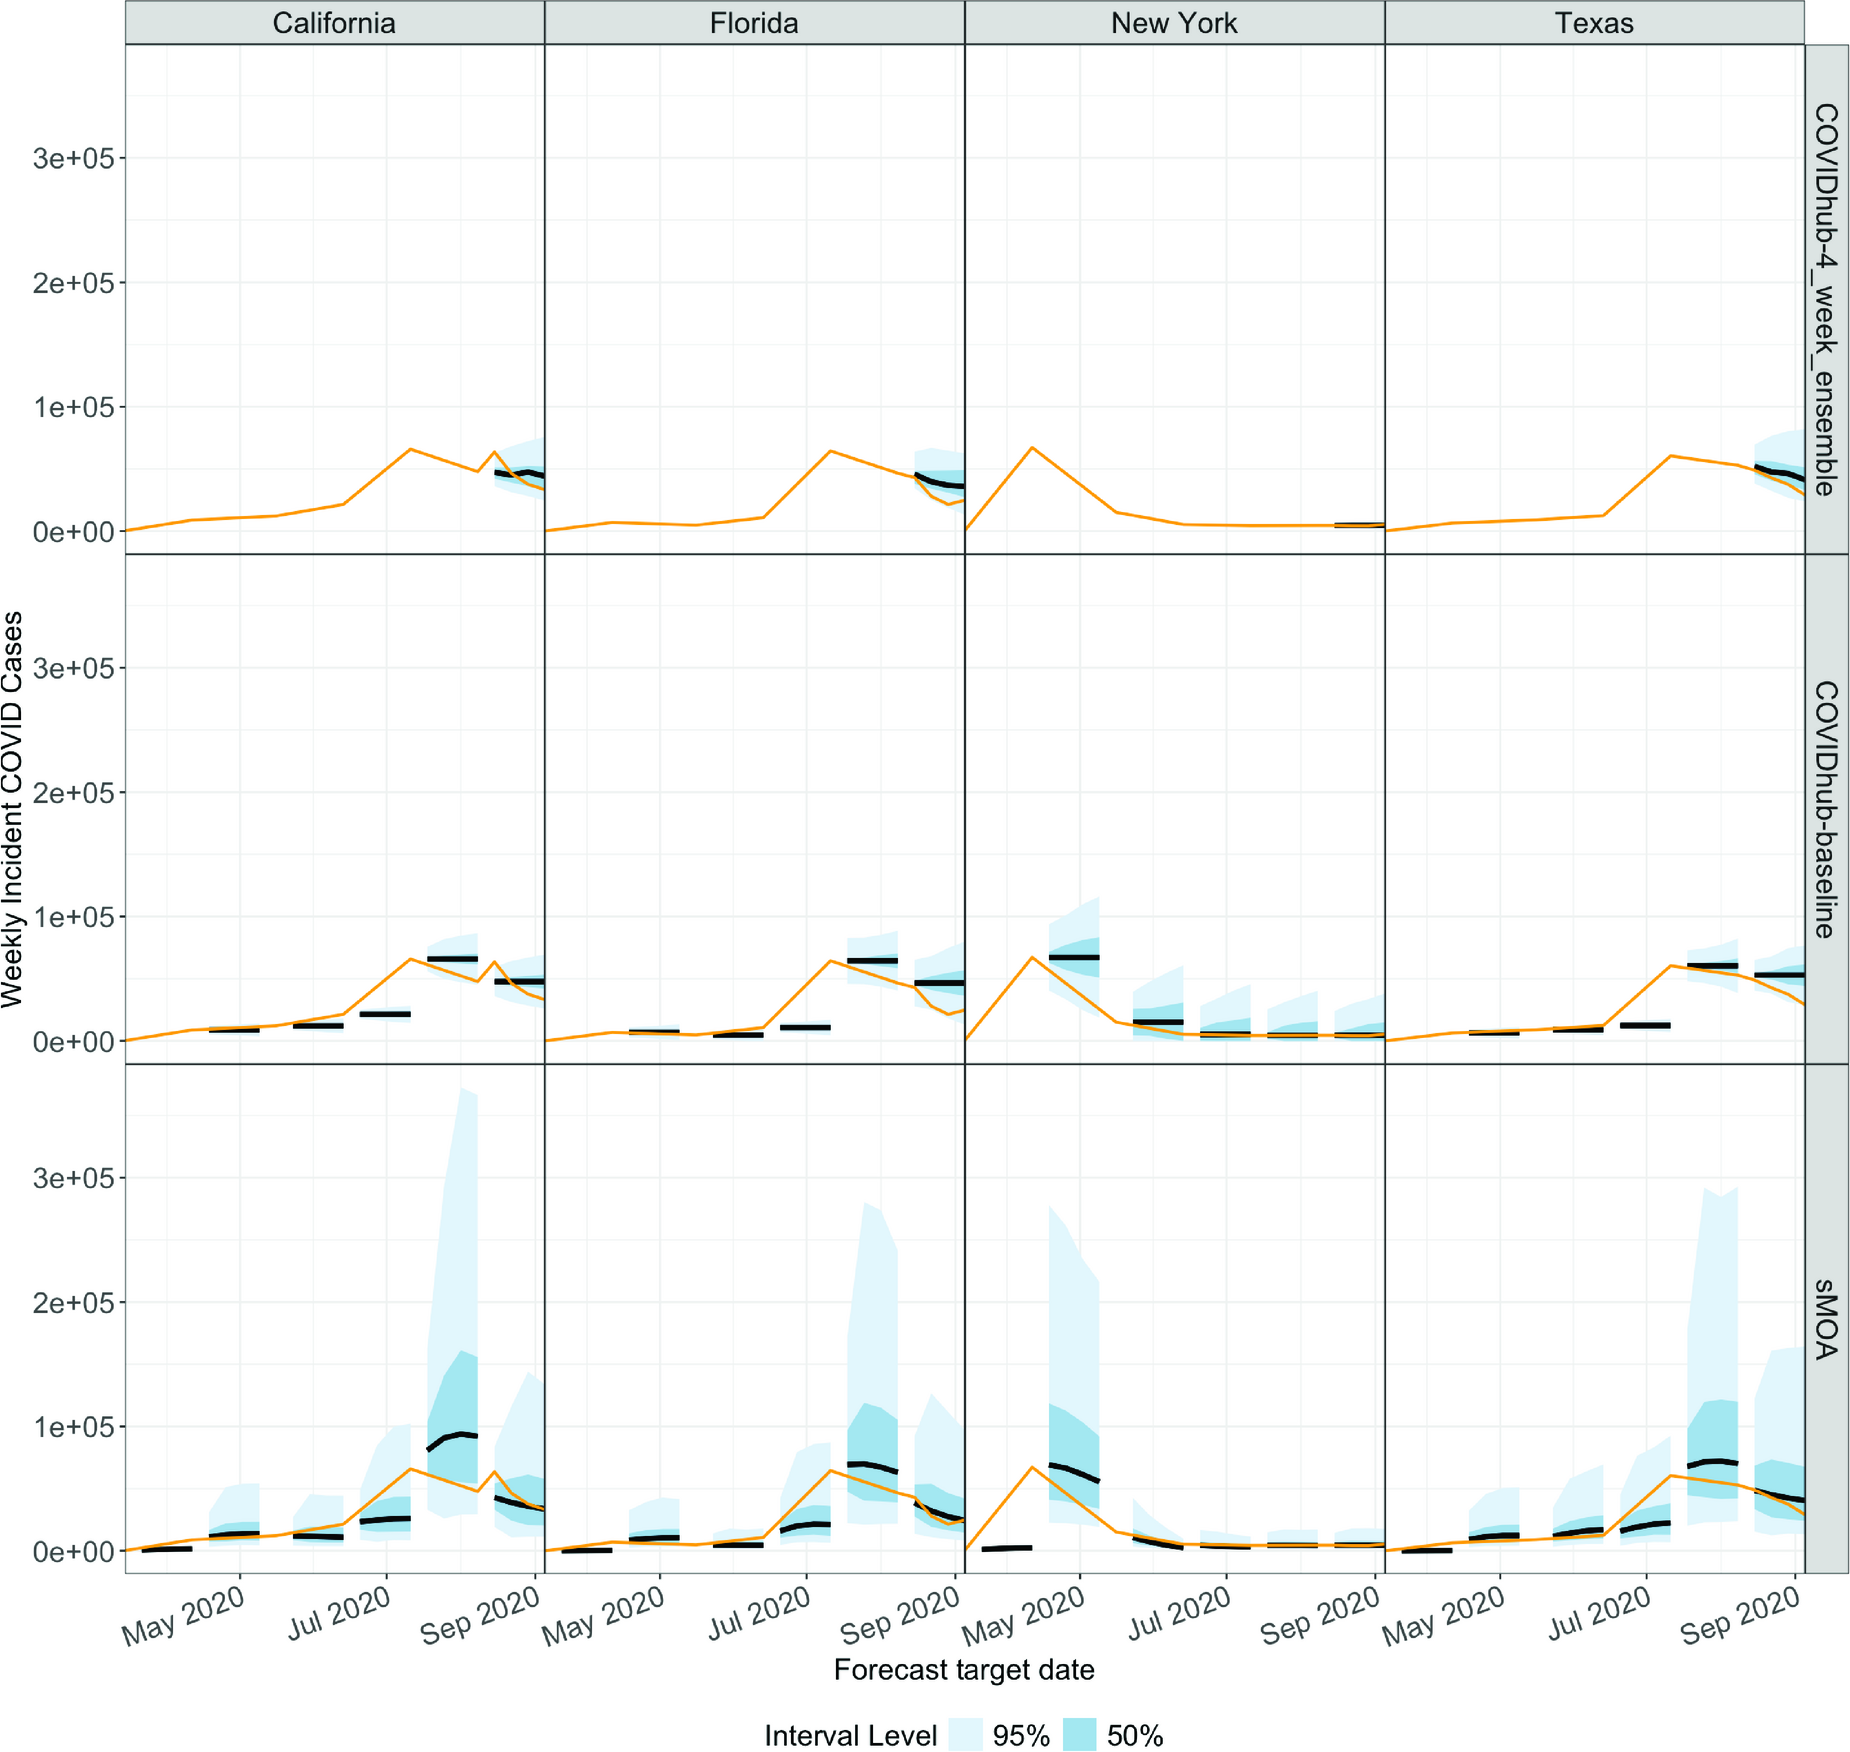

**Python — đúng bố cục và cùng nguồn historical data**

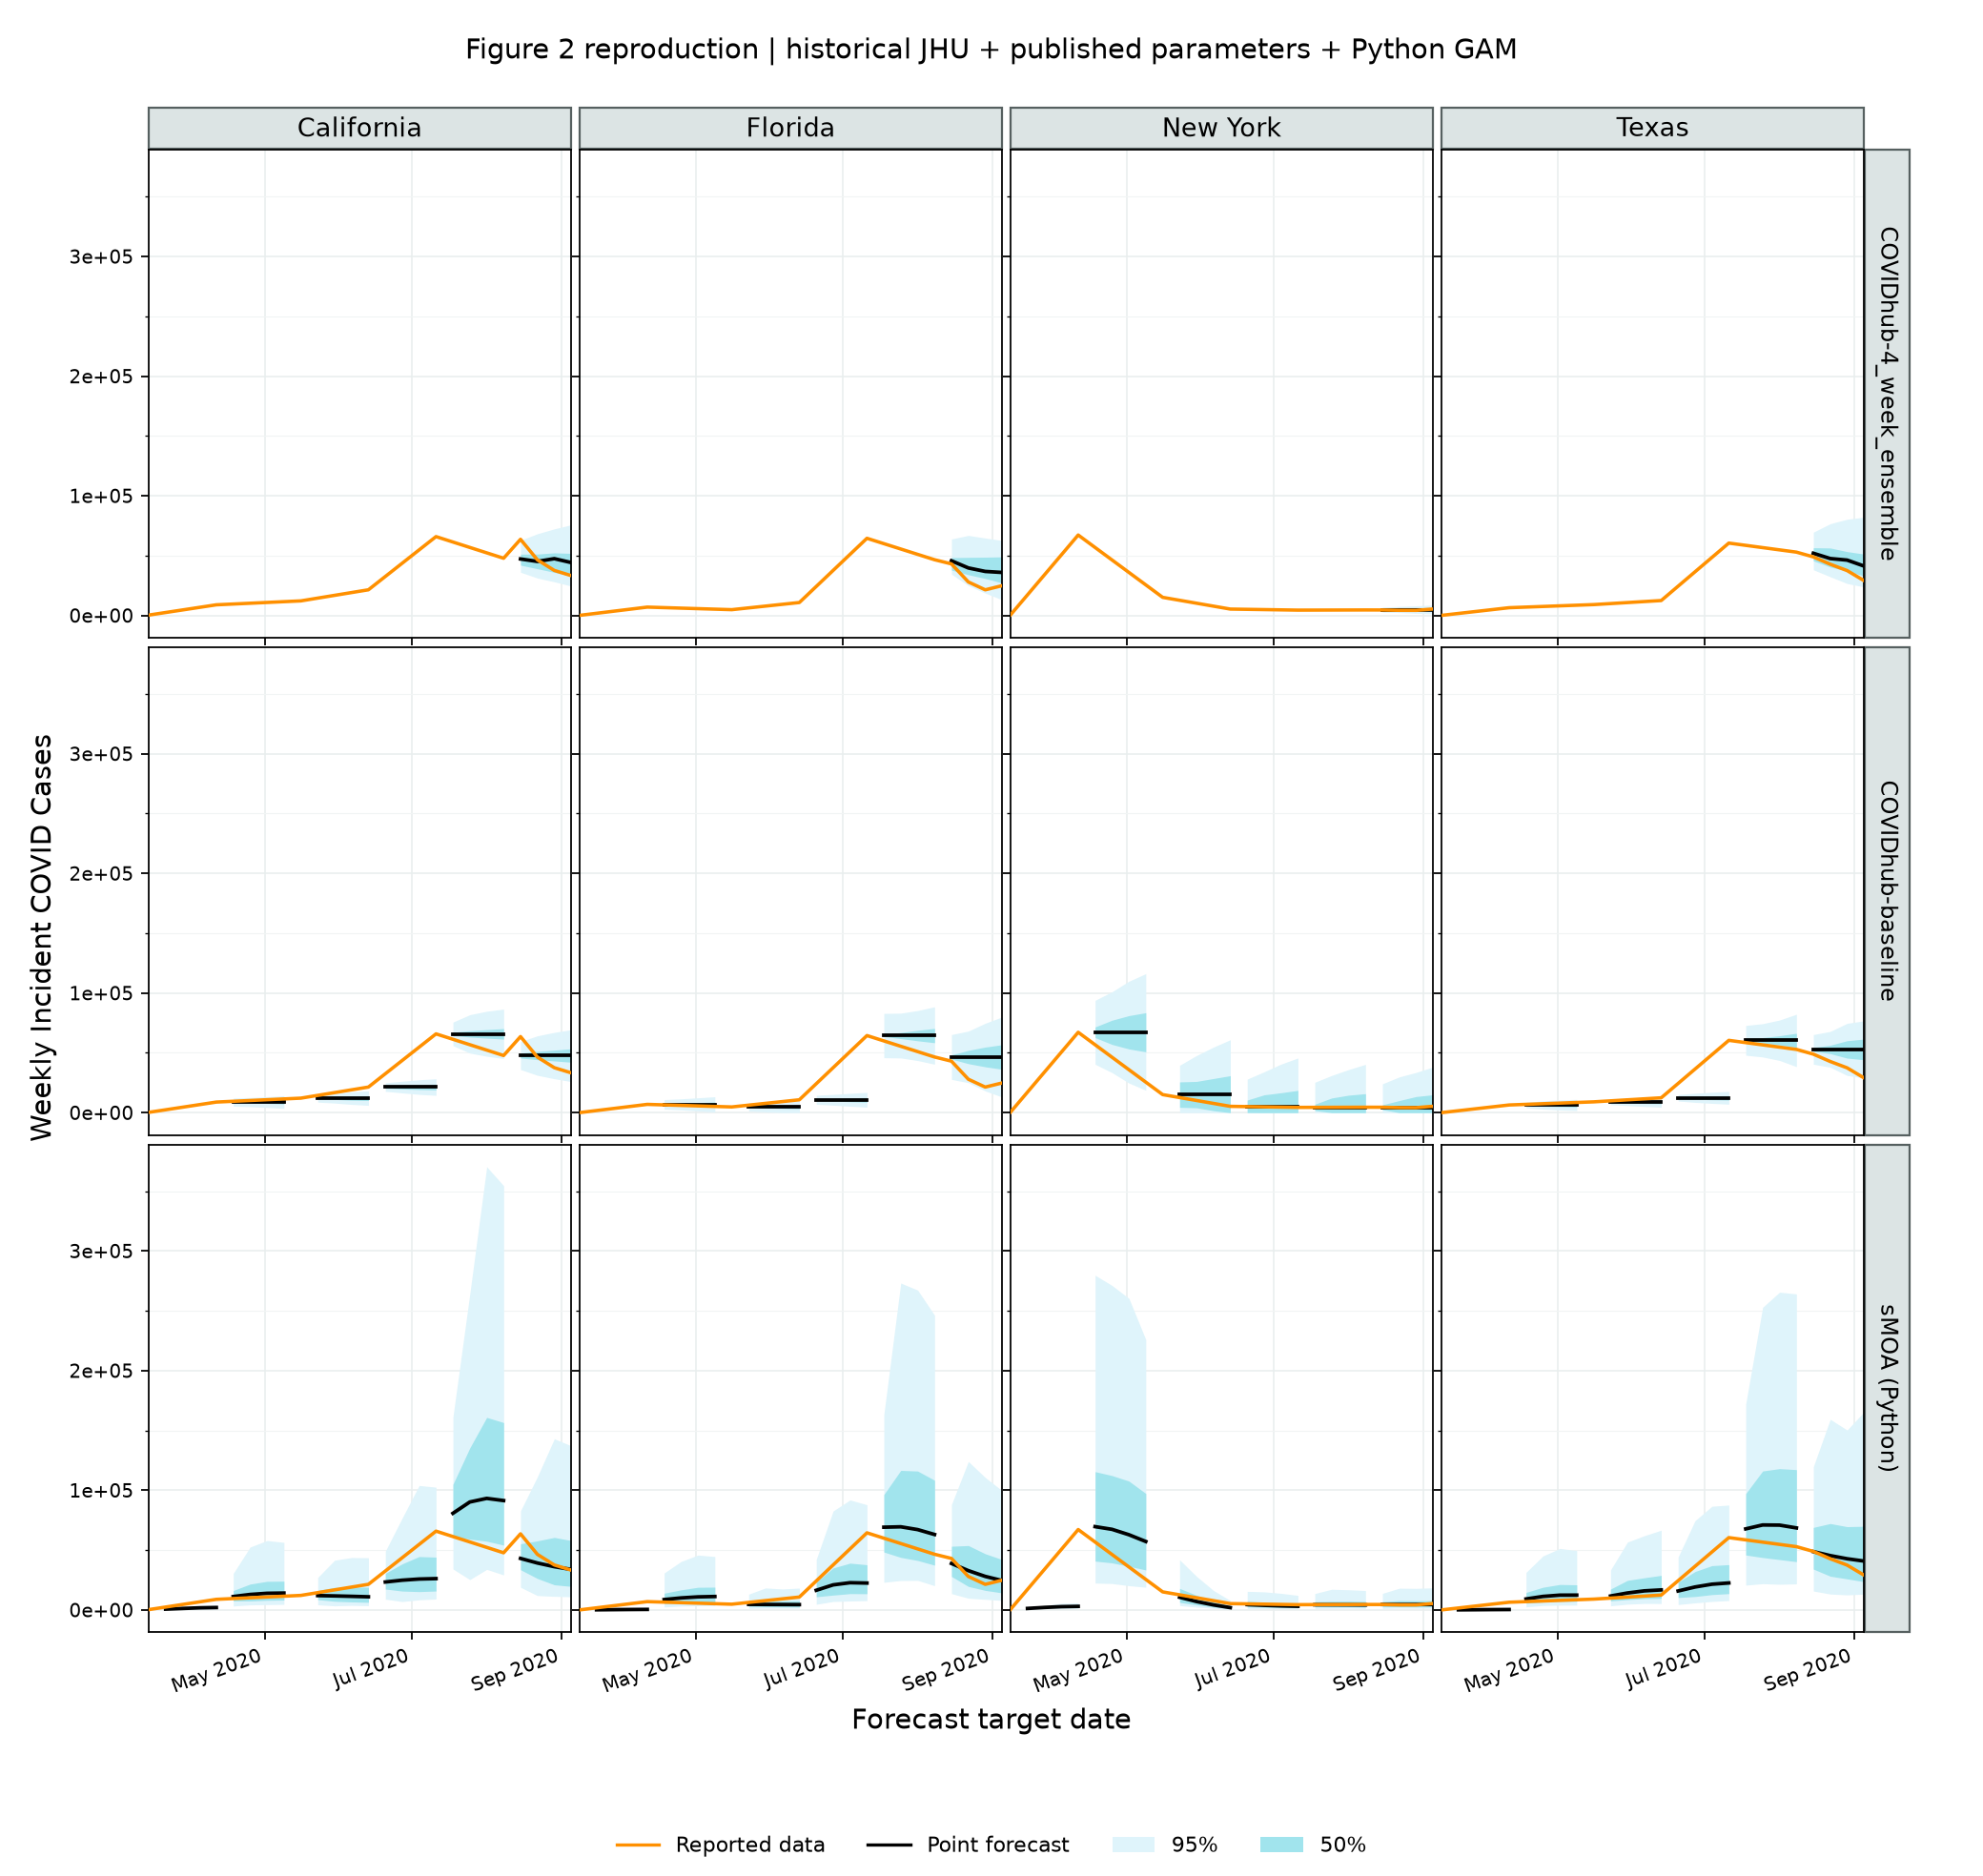

In [6]:
reference=OUT/'reference/paper_figure_2.png'
if reference.exists():
    display(Markdown('**Paper Figure 2 — PLOS, CC0**'))
    display(Image(filename=str(reference),width=1100))
display(Markdown('**Python — đúng bố cục và cùng nguồn historical data**'))
display(Image(filename=str(OUT/'figure_2_python.png'),width=1100))

## 6. Ablation và giới hạn kết luận

Cùng 96 targets, cùng library và hyperparameters. Báo cả final/historical ×
spline/GAM; không chọn biến thể theo lỗi COVID để làm score đẹp hơn. Dữ liệu
đúng nguồn có thể cho MAE cao hơn run cũ dùng final revisions.

Chưa có vector sMOA R gốc hay fitted-value fixtures mgcv; chưa xác nhận numerical
parity. Full 50 bang và ranking/calibration Figure 3–5 chưa được chạy lại với
protocol mới. Không dùng 104 trials legacy để khẳng định BO GAM đã hoàn tất.

In [7]:
display(pd.read_csv(OUT/'ablation.csv').round(3))
display(pd.DataFrame({'remaining':summary['remaining']}))
display(Markdown((OUT/'report.md').read_text()))

,variant,n,mae
0,final_gam,96,11009.385
1,final_spline,96,10377.401
2,historical_gam,96,10570.349
3,historical_spline,96,10873.130


,remaining
0,NumPy RNG versus R RNG; original generated lib...
1,Python thin plate/GCV optimizer not yet numeri...
2,Full 50-state historical-vintage experiment an...


# Experiment 0 — source-aligned Figure 2

Paper: [Murph et al.](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1013203); [README nguồn](https://github.com/lanl/precog/tree/main/smoa).

## Dữ liệu thực sự đã lấy

- JHU issue 2020-08-16, SHA cố định trong danh mục `reichlab/covidData`; gắn nhãn snapshot 2020-08-15 như `get_data_as_of.R`.
- Tổng county theo bang → sai phân cumulative → tổng tuần Chủ nhật–Thứ bảy; bỏ tuần chưa đủ. Không thay historical bằng final truth.
- Forecast gốc `COVIDhub-baseline` và `COVIDhub-4_week_ensemble`, đúng Monday submission và incident-case targets. Nguồn thiếu forecast thì giữ thiếu.
- Scoring truth vẫn là state_truths do LANL cung cấp, đọc bằng Python; provenance/URL/SHA ở `outputs/paper_data/provenance.json`.

## Sửa phương pháp

- Smoothing dùng thin plate regression spline với rank round(n/2), affine null space, curvature penalty và GCV; bỏ thay thế bằng natural smoothing spline.
- Published reference: 18.387 attempts/family, 55.161 attempts, 54.081 accepted; k=5, closest=4.422. Không lấy BO winner khác tham số công bố.
- Embedding bỏ bridge và NB sizes [20,10,6,6] theo nhánh Figure 2. Start Feb29, không thêm warmup khi source condition không thỏa.
- Figure 2 gốc cập nhật NB bằng tất cả forecast đã phát trước đó và final outcomes, kể cả target chưa tới. Chế độ `figure2_retrospective` tái hiện quy tắc này; đây là đánh giá hồi cứu, có sử dụng future labels trong UQ.
- Có đối chứng `smoa_matured_uq`: chỉ đổi UQ sang matured targets; giữ nguyên point forecast. Default forecasting ngoài experiment vẫn dùng matured.
- Bố cục 3 hàng model × 4 cột bang, chung trục y, đường thực tế màu cam, forecast màu đen, bands 50/95 xanh theo hình gốc.
- GCV chọn theo history, không chọn smoother/params theo lỗi COVID. Các ablation đều được công bố dù điểm tốt hay xấu.

## MAE/WIS — 7 quantiles giống Figure 2

Bảng dưới có số forecast khác nhau do COVIDHub chưa cung cấp case forecasts ở nhiều ngày early. **Không dùng bảng này để xếp hạng model.**

| model | n | mae | wis | coverage_95 |
| --- | --- | --- | --- | --- |
| COVIDhub-4_week_ensemble | 16 | 8,990.12 | 4,775.14 | 0.88 |
| COVIDhub-baseline | 80 | 10,946.83 | 7,921.12 | 0.70 |
| persistence | 96 | 11,590.70 | 8,612.02 | 0.78 |
| smoa | 96 | 10,570.35 | 7,431.19 | 0.83 |
| smoa_matured_uq | 96 | 10,570.35 | 7,447.89 | 0.83 |

## So sánh đúng giao các target có đủ 3 mô hình

| model | n | mae | wis |
| --- | --- | --- | --- |
| COVIDhub-4_week_ensemble | 16 | 8,990.12 | 4,775.14 |
| COVIDhub-baseline | 16 | 12,552.38 | 7,368.12 |
| smoa | 16 | 6,166.38 | 5,331.16 |

## Ablation dữ liệu và smoothing — cùng 96 targets

| variant | n | mae |
| --- | --- | --- |
| final_gam | 96 | 11,009.39 |
| final_spline | 96 | 10,377.40 |
| historical_gam | 96 | 10,570.35 |
| historical_spline | 96 | 10,873.13 |

## Phạm vi kết luận

Figure 2 hiện được dựng bằng dữ liệu lịch sử thật và cùng cấu trúc thuật toán/bố cục. Chưa có vector sMOA gốc để tính sai khác số trực tiếp với R; không khẳng định đã khớp tuyệt đối hay đạt calibration/ranking Figure 3–5.
Python dùng NumPy RNG/LSODA, library số khác R; thin plate/GCV cùng mô hình toán nhưng chưa có fixture fitted values của mgcv để xác nhận numerical parity.
Run 50 bang/104 BO evaluations cũ dùng final truth và legacy spline; không đổi nhãn thành kết quả mới. BO/forecast mặc định mới dùng GAM; muốn full run đúng protocol phải chạy thư mục mới.
Source Figure 2 ở commit trước publication `2018f2e` (2025-05-22) có cùng các lựa chọn trên. Script có đối số helper `current_end_date` không tồn tại, nhưng nhánh đó không chạy vì chỉ có 5 tuần trước Feb28.

![Python Figure 2](figure_2_python.png)

Kiểm tra dữ liệu bảng: `scores.csv`, `paired_scores.csv`, `plot_data.csv`, `ablation_predictions.csv`; protocol và input/source hashes: `protocol.json`.
